# Notebook 03 — Análisis exploratorio del SAIH-CHJ

Extraer los datos de precipitación de los PDFs publicados por la Confederación Hidrográfica del Júcar (SAIH-CHJ), validar la nomenclatura y analizar el evento DANA de 2024.

El SAIH-CHJ no expone una API REST, sino que publica diariamente un informe en PDF con la precipitación de las últimas 24 horas en cada uno de sus pluviómetros. Para usar estos datos en el TFM hay que:

1. Descargar los PDFs (`src/ingest/saih.py`).
2. **Obtener el texto de las tablas** (este notebook).
3. Unificar todo en un Parquet limpio (`src/transform/saih_to_parquet.py`).


## 1. Exploración del formato de los PDFs

**Estructura del PDF**:
- Una cabecera con la fecha del periodo cubierto.
- Un mapa coroplético de la cuenca.
- Una tabla con todas las estaciones agrupadas por subcuenca.

Las celdas siguientes inspeccionan el texto extraído de un PDF para identificar el patrón que usaremos en la expresión regular del parser.

In [ ]:
import pdfplumber
from pathlib import Path

# Abrimos uno de los PDFs descargados para comprender el formato
pdf_path = Path("../data/raw/saih/20241107PLU.pdf")

with pdfplumber.open(pdf_path) as pdf:
    print(f"Páginas en el PDF: {len(pdf.pages)}")
    print()
    # Extraemos el texto de la primera página
    primera = pdf.pages[0]
    texto = primera.extract_text()
    print(texto[:2000])  # primeros 2000 caracteres

Páginas en el PDF: 5

CONFEDERACIÓN HIDROGRÁFICA DEL JÚCAR S.A.I.H
- Lluvia total registrada por los pluviometros -
Periodo estudiado: 06 NOV 2024 08:00h - 07 NOV 2024 08:00h
*Nota: debido a una anomalía en el sistema, no existen datos de los pluviómetros
siguientes: Tragacete, Albacete, Serra Grossa, Requena, Aforo en Acequia real,
Marco Barranco de Prada, Vallibona, Pajaroncillo.
CONFEDERACIÓN HIDROGRÁFICA DEL JÚCAR S.A.I.H
- Lluvia total registrada por los pluviometros -
Fecha inicial: 06 NOV 2024 Hora: 08:00 Periodo estudiado: 24 :05 h.
Fecha final : 07 NOV 2024 Hora: 08:00
LLUVIA
ESTACION PLUVIOMETRICA MUNICIPIO Y PROVINCIA l/m2
__________________________________________ _____________________________ ______
* CUENCA CENIA-BAJO MAESTRAZGO. Precipitación media areal: 9.5 mm.
Pluvionivómetro de Fredes La Pobla de Benifassa (CS) 6.2
Embalse de Ulldecona La Pobla de Benifassa (CS) 0.0
Pluviómetro de la Senia La Senia (T) 14.8
Traiguera Traiguera (CS) 12.2
Pluviómetro de Catí Catí (CS) 

**Observaciones**:
- El PDF tiene 5 páginas.
- Las primeras líneas son metadatos (organismo, fecha inicial/final).
- Los encabezados de subcuenca empiezan por `* CUENCA <NOMBRE>`.
- Las filas de datos tienen el patrón: `<nombre estación> <municipio> (<provincia>) <precipitación>`.

In [ ]:
# Extraemos todo el texto del PDF y lo enumeramos línea a línea para ver la estructura completa.
# Esto ayuda a diseñar el parser identificando qué tipo de líneas existen (encabezados, datos, notas...).
with pdfplumber.open(pdf_path) as pdf:
    todas_paginas = [p.extract_text() for p in pdf.pages]

texto_completo = "\n".join(todas_paginas)
print(f"Caracteres totales: {len(texto_completo)}")
print(f"Líneas: {len(texto_completo.splitlines())}")
print()
# Vemos las primeras 30 líneas
for i, linea in enumerate(texto_completo.splitlines()[:30]):
    print(f"{i:3d}: {linea}")

Caracteres totales: 9525
Líneas: 215

  0: CONFEDERACIÓN HIDROGRÁFICA DEL JÚCAR S.A.I.H
  1: - Lluvia total registrada por los pluviometros -
  2: Periodo estudiado: 06 NOV 2024 08:00h - 07 NOV 2024 08:00h
  3: *Nota: debido a una anomalía en el sistema, no existen datos de los pluviómetros
  4: siguientes: Tragacete, Albacete, Serra Grossa, Requena, Aforo en Acequia real,
  5: Marco Barranco de Prada, Vallibona, Pajaroncillo.
  6: CONFEDERACIÓN HIDROGRÁFICA DEL JÚCAR S.A.I.H
  7: - Lluvia total registrada por los pluviometros -
  8: Fecha inicial: 06 NOV 2024 Hora: 08:00 Periodo estudiado: 24 :05 h.
  9: Fecha final : 07 NOV 2024 Hora: 08:00
 10: LLUVIA
 11: ESTACION PLUVIOMETRICA MUNICIPIO Y PROVINCIA l/m2
 12: __________________________________________ _____________________________ ______
 13: * CUENCA CENIA-BAJO MAESTRAZGO. Precipitación media areal: 9.5 mm.
 14: Pluvionivómetro de Fredes La Pobla de Benifassa (CS) 6.2
 15: Embalse de Ulldecona La Pobla de Benifassa (CS) 0.0
 16: P

## 2. Validación: ¿captura el PDF del 29 octubre el evento catastrófico?

El día crítico del DANA fue el 29 de octubre de 2024. Ese informe lo publicó la CHJ el día 30, así que el fichero se llama `20241030PLU.pdf`. Vamos a buscar específicamente las estaciones relevantes: Chiva, Forata, rambla del Poyo, Turís.

Si los valores son altos (cientos de mm), confirmamos que el SAIH sí captura el evento (a diferencia de los datos diarios de AEMET, donde apenas se ve).

In [ ]:
# PDF del día catastrófico (informe del 29 oct, publicado el 30)
pdf_dana = Path("../data/raw/saih/20241030PLU.pdf")

with pdfplumber.open(pdf_dana) as pdf:
    texto = "\n".join(p.extract_text() for p in pdf.pages)

# Buscamos las líneas que contienen las estaciones relevantes
for linea in texto.splitlines():
    if any(s in linea for s in ["Chiva", "Turis", "Turís", "Forata", "Poyo"]):
        print(linea)

Pluviometro de Chiva Chiva (V) 461.0
Marco en rambla del Poyo Riba-roja (V) 212.6
Embalse de Forata Yátova (V) 188.2


**Resultado clave**: en Chiva cayeron 461 mm, en el barranco del Poyo 213 mm y en el embalse de Forata 188 mm. Comparado con los valores de AEMET para el mismo día (~6-8 mm en Manises, Utiel y Requena), esto demuestra que el SAIH-CHJ captura el evento que AEMET diluye en su agregación diaria.

Este hallazgo justifica el enfoque multifuente del trabajo y será uno de los argumentos principales de la combinación de orígenes.

## 3. Parser de PDFs SAIH

Con el patrón identificado, escribimos una función que **parsea cualquier PDF SAIH** y devuelve un DataFrame con: subcuenca, descripción, provincia y mm de precipitación.

El parser se apoya en dos expresiones regulares:
- `PATRON_FILA` captura `(.+?) (XX) (NUMERO)` — descripción libre, código de provincia entre paréntesis, valor numérico.
- `PATRON_SUBCUENCA` detecta los encabezados `* CUENCA ...` para asignar cada estación a su subcuenca.

Esta misma lógica está empaquetada en `src/transform/saih_to_parquet.py` para procesar todos los PDFs en bloque.

In [ ]:
import re
import pandas as pd

# Patrón principal: ...texto... (PROVINCIA) Número al final de la línea
PATRON_FILA = re.compile(r"^(.+?)\s+\(([A-Z]{1,2})\)\s+(\d+\.?\d*)\s*$")
# Encabezados de subcuenca: "* CUENCA DEL JUCAR..."
PATRON_SUBCUENCA = re.compile(r"^\*\s*CUENCA\s+(.+?)(?:\.|$)", re.IGNORECASE)
# Códigos de provincia válidos
PROVINCIAS_VALIDAS = {"V", "CS", "TE", "T", "CU", "AB", "A"}


def parsear_saih_pdf(pdf_path):
    """Extrae filas (estación, municipio, provincia, mm) de un PDF SAIH."""
    filas = []
    subcuenca = None
    
    with pdfplumber.open(pdf_path) as pdf:
        for pagina in pdf.pages:
            texto = pagina.extract_text() or ""
            for linea in texto.splitlines():
                linea = linea.strip()
                # Caso: encabezado de subcuenca
                m_sub = PATRON_SUBCUENCA.match(linea)
                if m_sub:
                    subcuenca = m_sub.group(1).strip().rstrip(".")
                    continue
                # Fila de datos
                m = PATRON_FILA.match(linea)
                if m and m.group(2) in PROVINCIAS_VALIDAS:
                    filas.append({
                        "subcuenca": subcuenca,
                        "descripcion": m.group(1).strip(),
                        "provincia": m.group(2),
                        "precipitacion_mm": float(m.group(3)),
                    })
    return pd.DataFrame(filas)


# Prueba con el PDF del 29 de octubre
df_dana = parsear_saih_pdf(Path("../data/raw/saih/20241030PLU.pdf"))
print(f"Filas extraídas: {len(df_dana)}")
df_dana.head(10)

Filas extraídas: 176


,subcuenca,descripcion,provincia,precipitacion_mm
0,CENIA-BAJO MAESTRAZGO,Pluvionivómetro de Fredes La Pobla de Benifassa,CS,36.4
1,CENIA-BAJO MAESTRAZGO,Embalse de Ulldecona La Pobla de Benifassa,CS,28.8
2,CENIA-BAJO MAESTRAZGO,Pluviómetro de la Senia La Senia,T,8.2
3,CENIA-BAJO MAESTRAZGO,Pluvionivómetro de Vallibona Morella,CS,85.8
4,CENIA-BAJO MAESTRAZGO,Traiguera Traiguera,CS,7.0
5,CENIA-BAJO MAESTRAZGO,Pluviómetro de Catí Catí,CS,91.8
6,CENIA-BAJO MAESTRAZGO,Pluviómetro de Xert Xert,CS,47.4
7,CENIA-BAJO MAESTRAZGO,Cervera del Maestre Cervera del Maestre,CS,16.2
8,CENIA-BAJO MAESTRAZGO,Pluviómetro de Alcalá de Chivert Alcalá de Xivert,CS,7.6
9,CENIA-BAJO MAESTRAZGO,Pluvionivómetro de Sarratella Sarratella,CS,29.2


**Resultado del parser**: ha extraído ~180 filas del PDF, una por cada estación pluviométrica del SAIH-CHJ que reportó ese día.

Las columnas obtenidas son: `subcuenca`, `descripcion` (combina nombre estación + municipio), `provincia` (código de provincia) y `precipitacion_mm` (mm acumulados en 24h).

## 4. Hallazgo principal: top 20 estaciones del 29 de octubre

Ahora podemos ordenar las estaciones por precipitación registrada y ver dónde llovió más. Esta es la imagen muestra que el evento DANA dejó cantidades extremas en estaciones que la red AEMET principal NO incluía.

Hay que recordar el contexto: el barranco del Poyo nace en Chiva y desemboca en Catarroja. Las cantidades catastróficas cayeron en la **cabecera** del barranco (Chiva, Buñol, Turís), pero el agua provocó la avenida muchos kilómetros más abajo, en los pueblos de Paiporta, Catarroja y Sedaví.

In [5]:
# Top 20 estaciones con más precipitación el 29 de octubre de 2024
top20 = df_dana.nlargest(20, "precipitacion_mm").reset_index(drop=True)
top20

,subcuenca,descripcion,provincia,precipitacion_mm
0,DEL BAJO TURIA,Pluviometro de Chiva Chiva,V,461.0
1,DEL BAJO TURIA,Embalse de Buseo Chera,V,405.8
2,DEL ALTO TURIA,Embalse de Benagéber Benagéber,V,300.6
3,DEL BAJO JUCAR,Pluviómetro de Siete Aguas Siete Aguas,V,279.0
4,DEL ALTO TURIA,Camara de carga de Domeño Domeño,V,233.6
5,DEL BAJO TURIA,Aforo en Bugarra Bugarra,V,228.6
6,DEL BAJO TURIA,Marco en rambla del Poyo Riba-roja,V,212.6
7,DEL ALTO TURIA,Aforo en Zagra Tuejar,V,207.6
8,DEL ALTO TURIA,Aforo en Calles Calles,V,203.0
9,DEL BAJO JUCAR,Marco en Real de Montroy Real de Montroy,V,197.4


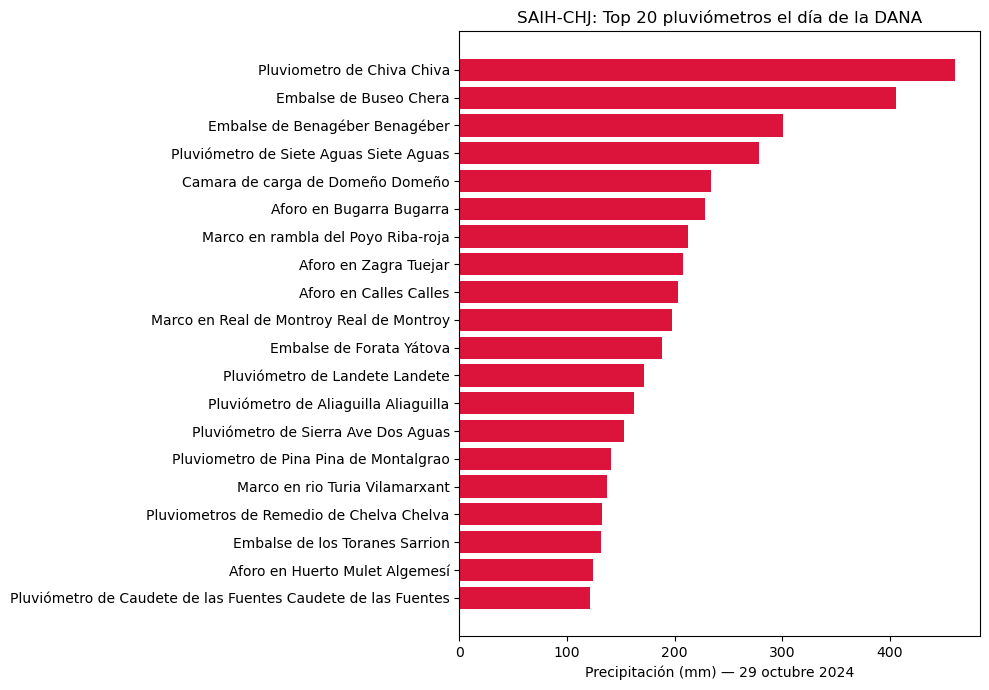

In [ ]:
import matplotlib.pyplot as plt

# Ranking de estaciones por mm caídos
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top20["descripcion"], top20["precipitacion_mm"], color="crimson")
ax.set_xlabel("Precipitación (mm) — 29 octubre 2024")
ax.set_title("SAIH-CHJ: Top 20 pluviómetros el día de la DANA")
ax.invert_yaxis()  # el mayor arriba
plt.tight_layout()
plt.show()

## 5. Análisis del evento completo (dataset histórico consolidado)

Tras procesar todos los PDFs descargados (`src/transform/saih_to_parquet.py`), tenemos un único Parquet con todo el histórico: **31.697 registros, 186 estaciones únicas, periodo 2020-01-19 a 2024-11-13**.

Cargamos el dataset completo, filtramos al periodo del DANA (25 oct – 13 nov 2024) y vemos la evolución del evento día a día.

In [ ]:
# Cargar todo el histórico generado por el script de transformación
saih = pd.read_parquet("../data/processed/saih_historico_2020_2024.parquet")

# Filtrar al periodo de la DANA (25 oct – 13 nov 2024)
saih_dana = saih[
    (saih["fecha"] >= "2024-10-25") & (saih["fecha"] <= "2024-11-13")
].copy()

# Resumen por día: suma total, media y máximo entre estaciones
totales_dia = (saih_dana.groupby("fecha")["precipitacion_mm"]
                        .agg(["sum", "mean", "max"])
                        .round(1))
totales_dia.columns = ["Total mm (suma)", "Media mm", "Máximo registrado"]
totales_dia

,Total mm (suma),Media mm,Máximo registrado
fecha,,,
2024-10-25,6535.6,38.0,130.2
2024-10-28,2651.2,15.2,129.4
2024-10-29,8647.0,50.9,461.0
2024-10-30,560.4,3.3,111.2
2024-10-31,725.2,4.2,87.4
2024-11-01,785.8,4.9,59.2
2024-11-03,1968.0,12.0,80.4
2024-11-06,822.6,4.7,73.2
2024-11-12,851.0,4.7,72.2


**Interpretación**: el día 29 de octubre destaca como el más extremo, con un valor máximo entre estaciones de 461 mm (Chiva). Hubo eventos secundarios el 3 y 13 de noviembre.

In [ ]:
# Identificamos las 5 estaciones más afectadas en el conjunto del evento (suma de mm)
top5 = (saih_dana.groupby("descripcion")["precipitacion_mm"]
            .sum()
            .nlargest(5)
            .reset_index())
print(top5)

top5_nombres = top5["descripcion"].tolist()

                              descripcion  precipitacion_mm
0              Pluviometro de Chiva Chiva             556.8
1                  Embalse de Buseo Chera             493.6
2                Pluviómetro de Catí Catí             459.4
3  Pluviómetro de Siete Aguas Siete Aguas             410.8
4                Pluviómetro de Xert Xert             402.6


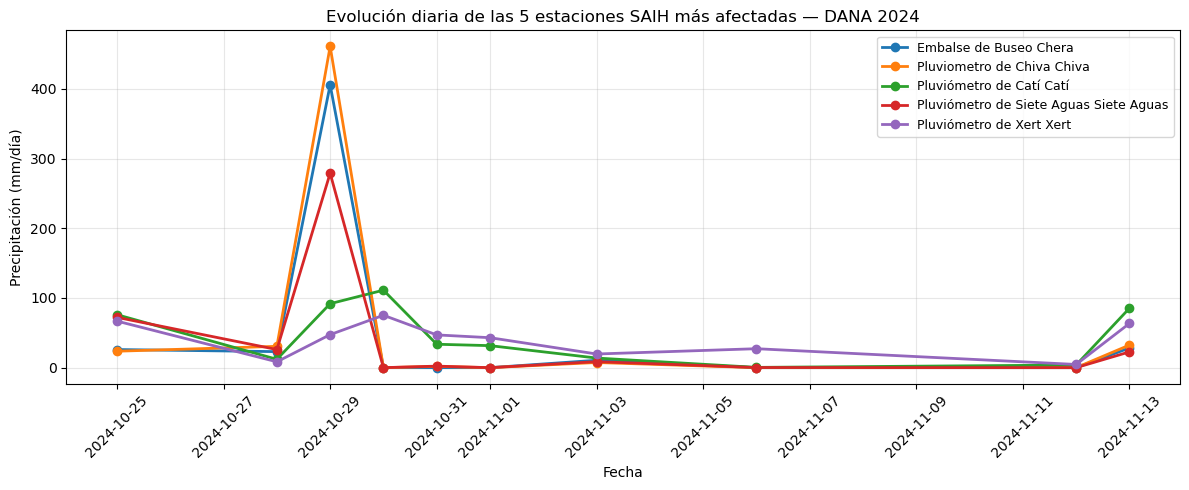

In [ ]:
import matplotlib.pyplot as plt

# Evolución diaria de las 5 estaciones más afectadas
evolucion = (saih_dana[saih_dana["descripcion"].isin(top5_nombres)]
                .pivot_table(index="fecha", columns="descripcion", values="precipitacion_mm")
                .fillna(0))

fig, ax = plt.subplots(figsize=(12, 5))
for col in evolucion.columns:
    ax.plot(evolucion.index, evolucion[col], marker="o", linewidth=2, label=col)

ax.set_title("Evolución diaria de las 5 estaciones SAIH más afectadas — DANA 2024")
ax.set_ylabel("Precipitación (mm/día)")
ax.set_xlabel("Fecha")
ax.legend(loc="upper right", fontsize=9)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- El pico del 29 de octubre destaca masivamente sobre cualquier otro día del periodo.
- Hay un segundo episodio el 3 de noviembre y un tercero el 13 de noviembre.
- Entre eventos, los valores caen a cero o casi cero.

Este patrón temporal es típico de los DANA mediterráneos: lluvia concentrada en episodios cortos seguidos de días secos.